# Projet 4 - Classification - domaine RH - EDA

## Les imports & chargement des csv

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from jbtools import describoost

df_sirh = pd.read_csv('extrait_sirh.csv')
df_eval = pd.read_csv('extrait_eval.csv')
df_sondage = pd.read_csv('extrait_sondage.csv')

In [9]:
print(str(df_sirh.info()).replace('non-null',''))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   id_employee                     1470 non-null   int64 
 1   age                             1470 non-null   int64 
 2   genre                           1470 non-null   object
 3   revenu_mensuel                  1470 non-null   int64 
 4   statut_marital                  1470 non-null   object
 5   departement                     1470 non-null   object
 6   poste                           1470 non-null   object
 7   nombre_experiences_precedentes  1470 non-null   int64 
 8   nombre_heures_travailless       1470 non-null   int64 
 9   annee_experience_totale         1470 non-null   int64 
 10  annees_dans_l_entreprise        1470 non-null   int64 
 11  annees_dans_le_poste_actuel     1470 non-null   int64 
dtypes: int64(8), object(4)
memory usage: 137.9+ KB
N

## Quick check fichiers sources

In [18]:
describoost(df_sirh,'df_sirh')


==================== 🚀 DESCRIBOOST : df_sirh ====================
Nbre de lignes  : 1470 
Nbre de colonnes: 12 

--- ANALYSE NUMÉRIQUE ---
                                 count     mean      std     min      25%     50%      75%      max  skewsc  mean/md Minidist  NaNs       Remarque   Suggestion
id_employee                     1470.0  1024.87   602.02     1.0   491.25  1020.5  1555.75   2068.0     0.0      1.0     ▄▄▄▄   0.0              -            -
age                             1470.0    36.92     9.14    18.0    30.00    36.0    43.00     60.0     0.3      1.0     ▄▄▄▄   0.0              -            -
revenu_mensuel                  1470.0  6502.93  4707.96  1009.0  2911.00  4919.0  8379.00  19999.0     2.9      1.3     ██▄_   0.0              -            -
nombre_experiences_precedentes  1470.0     2.69     2.50     0.0     1.00     2.0     4.00      9.0     2.5      1.3     ██▄_   0.0              -            -
annee_experience_totale         1470.0    11.28     7.78    

In [3]:
describoost(df_eval,'df_eval')


==================== 🚀 DESCRIBOOST : df_eval ====================
Nbre de lignes  : 1470 
Nbre de colonnes: 10 

--- ANALYSE NUMÉRIQUE ---
                                            count  mean   std  min  25%  50%  75%  max skewsc  mean/md Minidist  NaNs Remarque Suggestion
satisfaction_employee_environnement        1470.0  2.72  1.09  1.0  2.0  3.0  4.0  4.0   -1.0      0.9     ▄▄▄█   0.0        -          -
note_evaluation_precedente                 1470.0  2.73  0.71  1.0  2.0  3.0  3.0  4.0   -1.0      0.9     ▄▄█▄   0.0        -          -
niveau_hierarchique_poste                  1470.0  2.06  1.11  1.0  1.0  2.0  3.0  5.0    2.0      1.0     █▄▄▄   0.0        -          -
satisfaction_employee_nature_travail       1470.0  2.73  1.10  1.0  2.0  3.0  4.0  4.0   -1.0      0.9     ▄▄▄█   0.0        -          -
satisfaction_employee_equipe               1470.0  2.71  1.08  1.0  2.0  3.0  4.0  4.0   -1.0      0.9     ▄▄▄█   0.0        -          -
satisfaction_employee_equilibre_

In [4]:
describoost(df_sondage,'df_sondage')


==================== 🚀 DESCRIBOOST : df_sondage ====================
Nbre de lignes  : 1470 
Nbre de colonnes: 12 

--- ANALYSE NUMÉRIQUE ---
                                      count     mean     std  min     25%     50%      75%     max  skewsc  mean/md Minidist  NaNs       Remarque   Suggestion
nombre_participation_pee             1470.0     0.79    0.85  0.0    0.00     1.0     1.00     3.0     1.0      0.8     █▄█_   0.0              -            -
nb_formations_suivies                1470.0     2.80    1.29  0.0    2.00     3.0     3.00     6.0     0.0      0.9     ▄▄█▄   0.0              -            -
code_sondage                         1470.0  1024.87  602.02  1.0  491.25  1020.5  1555.75  2068.0     0.0      1.0     ▄▄▄▄   0.0              -            -
distance_domicile_travail            1470.0     9.19    8.11  1.0    2.00     7.0    14.00    29.0     2.7      1.3     █▄▄_   0.0              -            -
niveau_education                     1470.0     2.91    1.02  

In [5]:
print('Nb unique id_employee : ' + str(df_sirh['id_employee'].nunique()))
print('Nb unique eval_number : ' + str(df_eval['eval_number'].nunique()))
print('Nb unique code_sondage : ' + str(df_sondage['code_sondage'].nunique()))

Nb unique id_employee : 1470
Nb unique eval_number : 1470
Nb unique code_sondage : 1470


<u>**À dropper:**</u>  
df_sirh.nombre_heures_travailless (constante à 80)  
df_sondage.nombre_employee_sous_responsabilite (constante à 1)  
df_sondage.ayant_enfant (constante à Y)  

<u>**À convertir:**</u>  
df_eval.augementation_salaire_precedente : string "11 %" → int  
df_eval.eval_number : string "E_1" → int pour la jointure  
df_sondage.a_quitte_l_entreprise : string "Yes"/"No" → 0/1  

## Creation du dataframe global (jointure des 3 sources)

In [6]:
# 1. On nettoie eval_number pour enlever le "E_" et transformer en nombre
df_eval['id_employee'] = df_eval['eval_number'].str.replace('E_', '').astype(int)

# 2. On renomme code_sondage pour uniformiser
df_sondage = df_sondage.rename(columns={'code_sondage': 'id_employee'})

# 3. La grande fusion (Inner Join sur l'ID)
df_global = df_sirh.merge(df_eval, on='id_employee').merge(df_sondage, on='id_employee')

# 4. Un petit coup de Describoost pour valider la fusion
describoost(df_global, the_name="Dataset Master df_global")


==================== 🚀 DESCRIBOOST : Dataset Master df_global ====================
Nbre de lignes  : 1470 
Nbre de colonnes: 33 

--- ANALYSE NUMÉRIQUE ---
                                            count     mean      std     min      25%     50%      75%      max skewsc  mean/md Minidist  NaNs       Remarque   Suggestion
id_employee                                1470.0  1024.87   602.02     1.0   491.25  1020.5  1555.75   2068.0    0.0      1.0     ▄▄▄▄   0.0              -            -
niveau_education                           1470.0     2.91     1.02     1.0     2.00     3.0     4.00      5.0      0      1.0     ▄▄▄▄   0.0              -            -
distance_domicile_travail                  1470.0     9.19     8.11     1.0     2.00     7.0    14.00     29.0    2.7      1.3     █▄▄_   0.0              -            -
nb_formations_suivies                      1470.0     2.80     1.29     0.0     2.00     3.0     3.00      6.0      0      0.9     ▄▄█▄   0.0              -       

### Suppression des colonnes inutiles

In [7]:
# Les colonnes à supprimer
cols_to_drop = [
    'ayant_enfants', 
    'nombre_employee_sous_responsabilite', 
    'nombre_heures_travailless', 
    'id_employee', 
    'eval_number'
]

df_global.drop(columns=cols_to_drop, inplace=True, errors='ignore')

print(f"Nettoyage terminé. Nouvelles dimensions : {df_global.shape}")

Nettoyage terminé. Nouvelles dimensions : (1470, 28)


### Rectif colonne "augementation_salaire_precedente" => "augmentation_salaire_prec_pct" (numerique)

In [8]:
# Correction du nom et nettoyage du contenu
df_global.rename(columns={'augementation_salaire_precedente': 'augmentation_salaire_prec_pct'}, inplace=True)

def clean_percentage(val):
    if isinstance(val, str):
        return float(val.replace('%', '').strip())
    return float(val)

df_global['augmentation_salaire_prec_pct'] = df_global['augmentation_salaire_prec_pct'].apply(clean_percentage)

### Rectif colonnes "a_quitte_l_entreprise" et "heure_supplementaires"

In [9]:
def encode_target(val):
    return 1 if (val == 'Oui') or (val ==1) else 0

df_global['a_quitte_l_entreprise'] = df_global['a_quitte_l_entreprise'].apply(encode_target)
df_global['heure_supplementaires'] = df_global['heure_supplementaires'].apply(encode_target)

## df_global => describoost

In [10]:
describoost(df_global, the_name="Dataset Master df_global", sorting_column='mean/md')


==================== 🚀 DESCRIBOOST : Dataset Master df_global ====================
Nbre de lignes  : 1470 
Nbre de colonnes: 28 

--- ANALYSE NUMÉRIQUE ---
                                            count     mean      std     min     25%     50%     75%      max skewsc mean/md Minidist  NaNs      Remarque   Suggestion
a_quitte_l_entreprise                      1470.0     0.16     0.37     0.0     0.0     0.0     0.0      1.0      +       .     ███_   0.0             -            -
heure_supplementaires                      1470.0     0.28     0.45     0.0     0.0     0.0     1.0      1.0      +       .     ██_█   0.0             -            -
nombre_participation_pee                   1470.0     0.79     0.85     0.0     0.0     1.0     1.0      3.0    1.0     0.8     █▄█_   0.0             -            -
satisfaction_employee_equipe               1470.0     2.71     1.08     1.0     2.0     3.0     4.0      4.0   -1.0     0.9     ▄▄▄█   0.0             -            -
nb_formations

## Quelques graphiques

Text(0.5, 1.0, 'Salaire vs Départ')

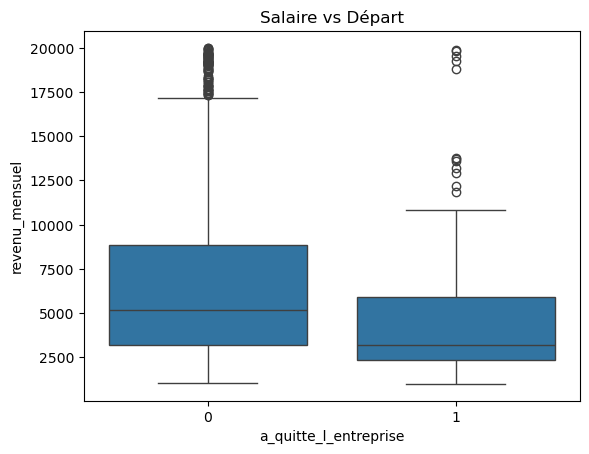

In [11]:
# Graphique 1 : Impact du revenu
sns.boxplot(data=df_global, x='a_quitte_l_entreprise', y='revenu_mensuel')
plt.title('Salaire vs Départ')



Text(0.5, 1.0, "Répartition de l'Âge")

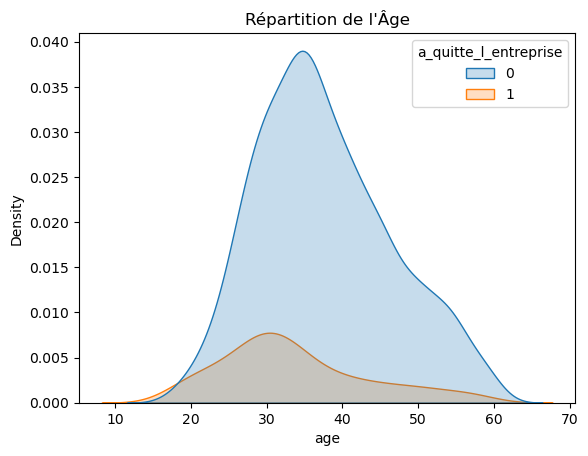

In [12]:

# Graphique 3 : Distribution de l'âge
sns.kdeplot(data=df_global, x='age', hue='a_quitte_l_entreprise', fill=True)
plt.title('Répartition de l\'Âge')


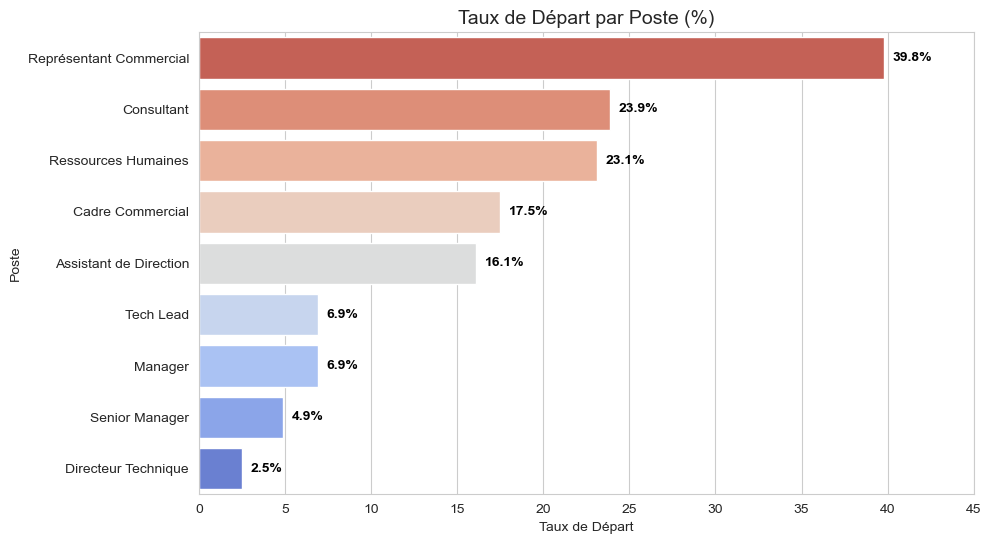

In [13]:
# Préparation des données (basée sur tes chiffres)
data = {
    'Poste': ['Représentant Commercial', 'Consultant', 'Ressources Humaines', 'Cadre Commercial', 
              'Assistant de Direction', 'Tech Lead', 'Manager', 'Senior Manager', 'Directeur Technique'],
    'Taux de Départ': [39.8, 23.9, 23.1, 17.5, 16.1, 6.9, 6.9, 4.9, 2.5]
}
df_plot = pd.DataFrame(data)

# Graphique
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")
bar_plot = sns.barplot(x='Taux de Départ', y='Poste', data=df_plot, hue='Poste', palette='coolwarm_r', legend=False)

# Ajout des labels de pourcentage
for i, v in enumerate(df_plot['Taux de Départ']):
    plt.text(v + 0.5, i, f'{v}%', color='black', va='center', fontweight='bold')

plt.title('Taux de Départ par Poste (%)', fontsize=14)
plt.xlim(0, 45) # Pour laisser de la place aux labels
plt.show()

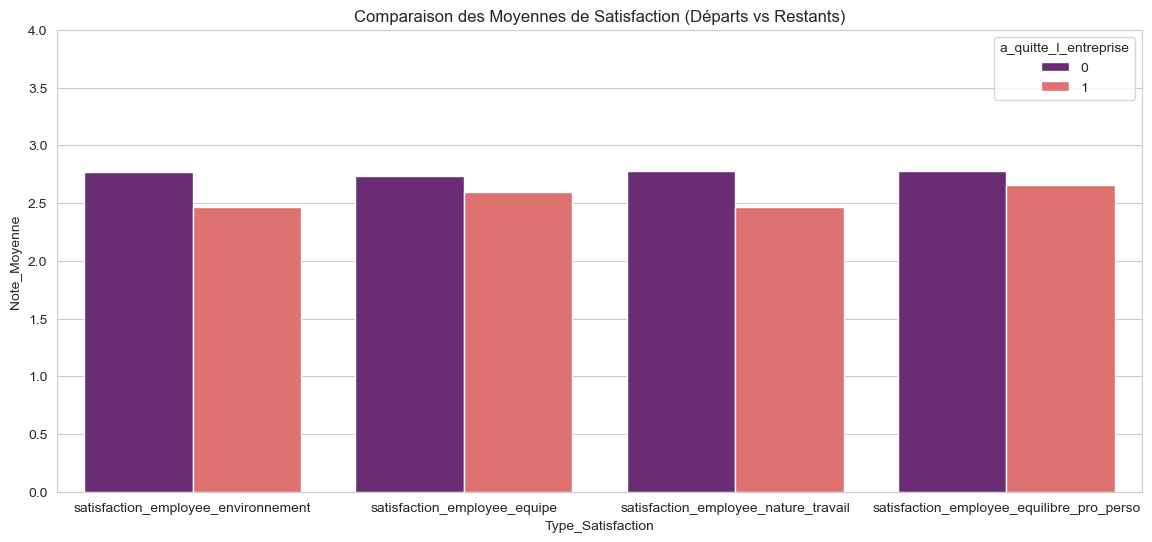

In [14]:
# Préparation des données pour comparer les 3 piliers
satisfaction_cols = [
    'satisfaction_employee_environnement', 
    'satisfaction_employee_equipe', 
    'satisfaction_employee_nature_travail',
    'satisfaction_employee_equilibre_pro_perso'
]

# Calcul des moyennes par groupe (0 ou 1)
df_satisfaction = df_global.groupby('a_quitte_l_entreprise')[satisfaction_cols].mean().reset_index()
df_melted = df_satisfaction.melt(id_vars='a_quitte_l_entreprise', var_name='Type_Satisfaction', value_name='Note_Moyenne')

plt.figure(figsize=(14, 6))
sns.barplot(data=df_melted, x='Type_Satisfaction', y='Note_Moyenne', hue='a_quitte_l_entreprise', palette='magma')
plt.title('Comparaison des Moyennes de Satisfaction (Départs vs Restants)')
plt.ylim(0, 4) # Les notes sont sur 4
plt.show()

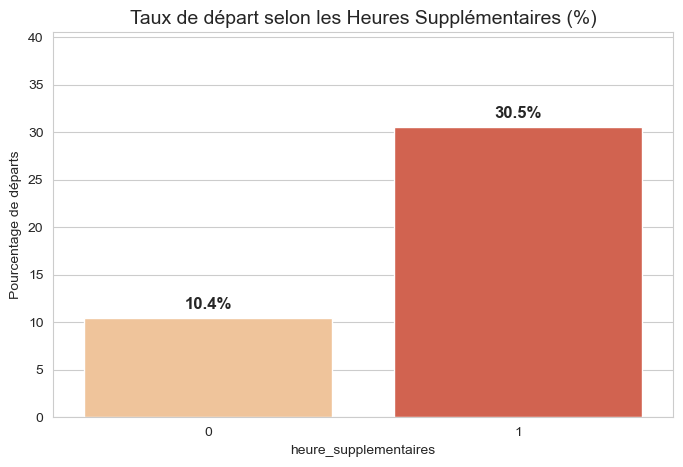

In [15]:
# 1. Calcul du ratio de départ par catégorie d'heures sup
ratio_hs = df_global.groupby('heure_supplementaires')['a_quitte_l_entreprise'].mean() * 100

# 2. Création du graphique
plt.figure(figsize=(8, 5))
sns.barplot(x=ratio_hs.index, y=ratio_hs.values, hue=ratio_hs.index, palette='OrRd', legend=False)

# 3. Ajout des étiquettes de pourcentage
for i, v in enumerate(ratio_hs.values):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=12)

plt.title('Taux de départ selon les Heures Supplémentaires (%)', fontsize=14)
plt.ylabel('Pourcentage de départs')
plt.ylim(0, max(ratio_hs.values) + 10) # Pour laisser de la place au texte
plt.show()

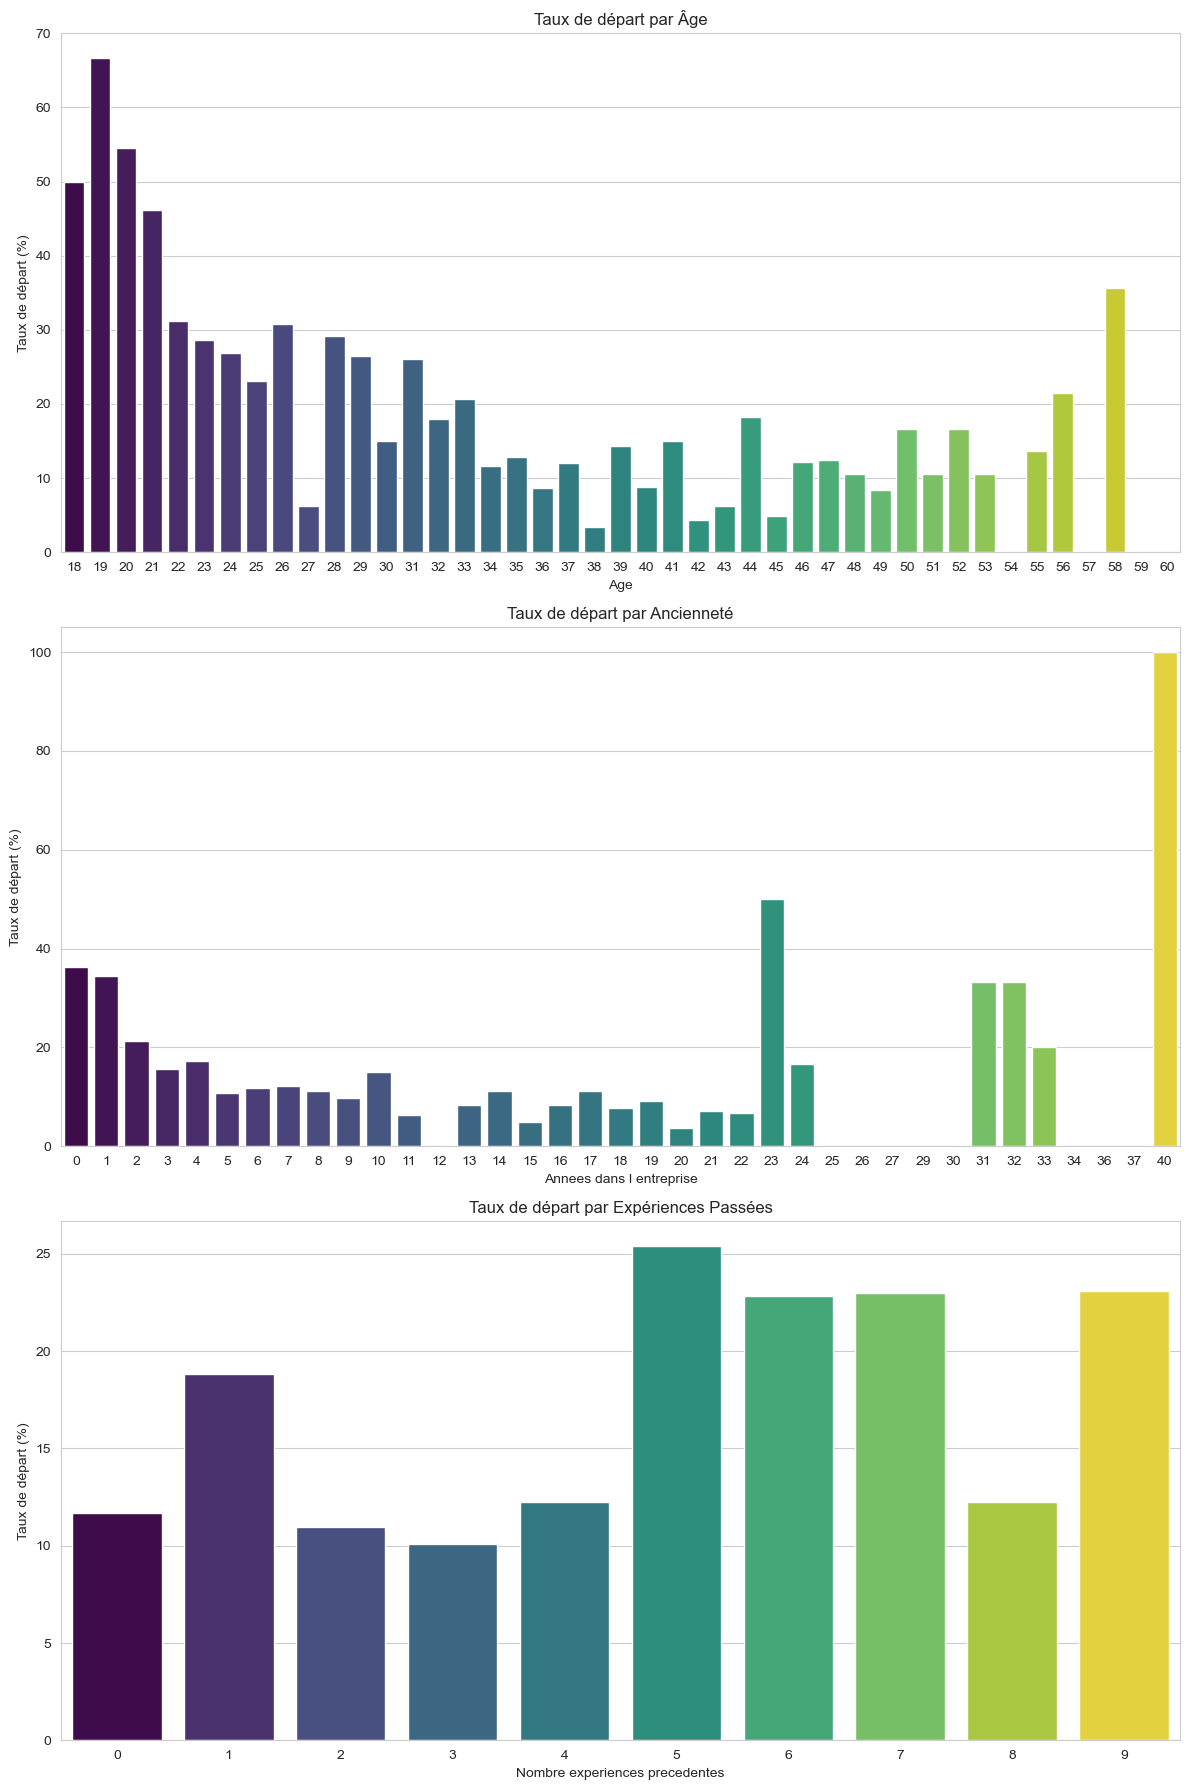

In [16]:
# On définit une fonction pour automatiser le calcul du ratio par tranche
def plot_departure_ratio(df, column, title, ax):
    # Calcul du ratio moyen de départ par valeur de la colonne
    ratio_data = df.groupby(column)['a_quitte_l_entreprise'].mean() * 100
    
    # Création du barplot
    sns.barplot(x=ratio_data.index, y=ratio_data.values, ax=ax, palette='viridis', hue=ratio_data.index, legend=False)
    ax.set_title(title)
    ax.set_ylabel('Taux de départ (%)')
    ax.set_xlabel(column.replace('_', ' ').capitalize())

fig, axes = plt.subplots(3, 1, figsize=(12, 18))

plot_departure_ratio(df_global, 'age', 'Taux de départ par Âge', axes[0])
plot_departure_ratio(df_global, 'annees_dans_l_entreprise', 'Taux de départ par Ancienneté', axes[1])
plot_departure_ratio(df_global, 'nombre_experiences_precedentes', 'Taux de départ par Expériences Passées', axes[2])

plt.tight_layout()
plt.show()

## Save df_global

In [17]:
df_global.to_parquet('df_expert.parquet')